In [1]:
!pip install -q ultralytics

In [2]:
import torch
import cv2
import ultralytics

print("PyTorch:", torch.__version__)
print("YOLO:", ultralytics.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.14.1+cu130
YOLO: 8.4.211
GPU available: True
GPU name: Tesla T4


In [3]:
import cv2
import os

video_path = "/content/input.mp4"

if not os.path.exists(video_path):
    print("Video not found. Please upload input.mp4.")
else:
    cap = cv2.VideoCapture(video_path)

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    duration = total_frames / fps if fps > 0 else 0

    print("Total frames:", total_frames)
    print("Original video FPS:", fps)
    print("Resolution:", width, "x", height)
    print("Duration:", round(duration, 2), "seconds")

    cap.release()

Total frames: 371
Original video FPS: 30.0
Resolution: 768 x 432
Duration: 12.37 seconds


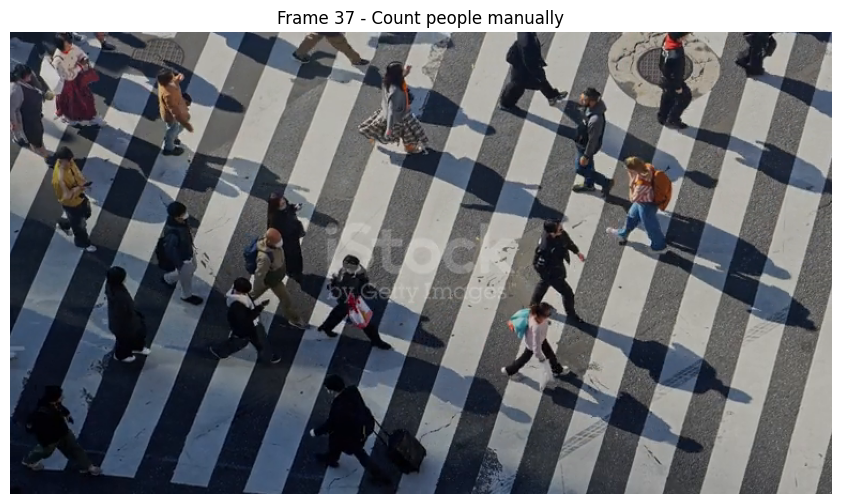

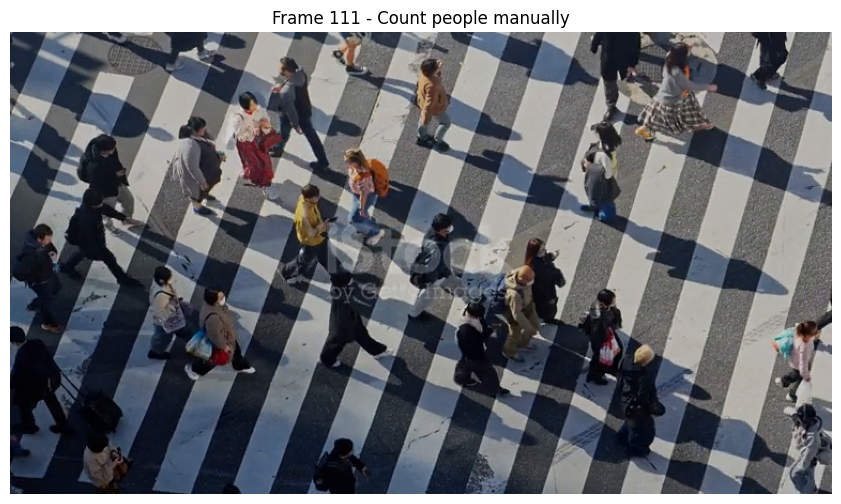

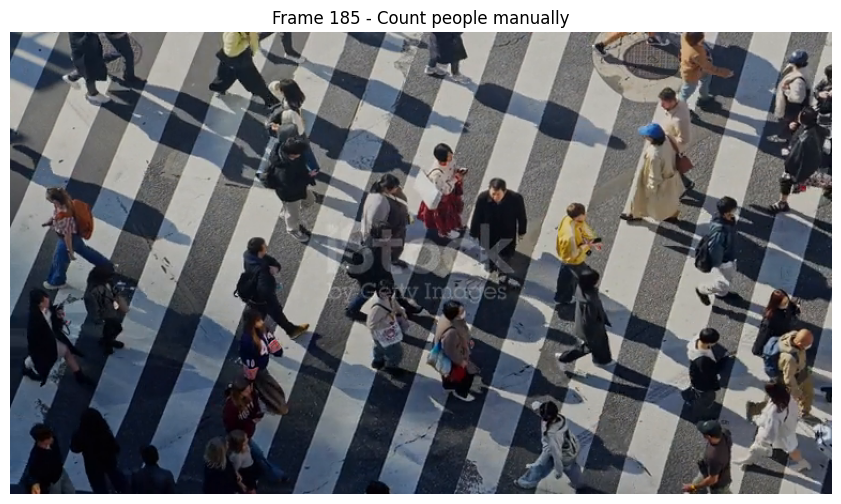

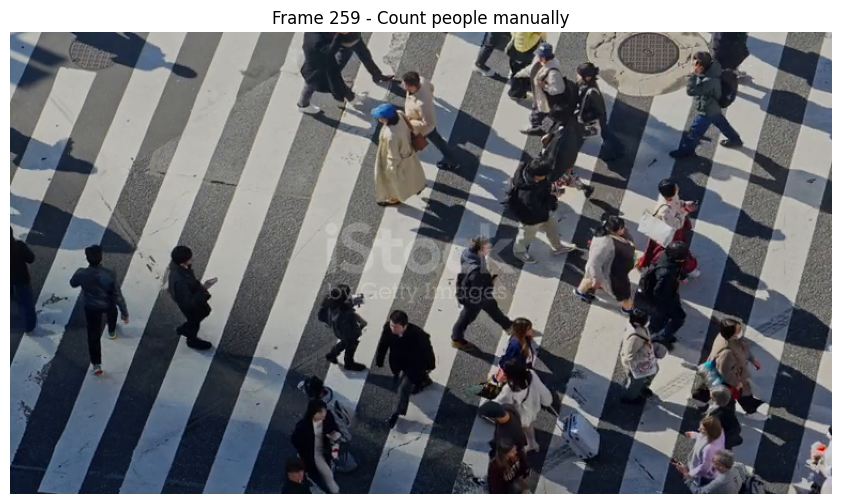

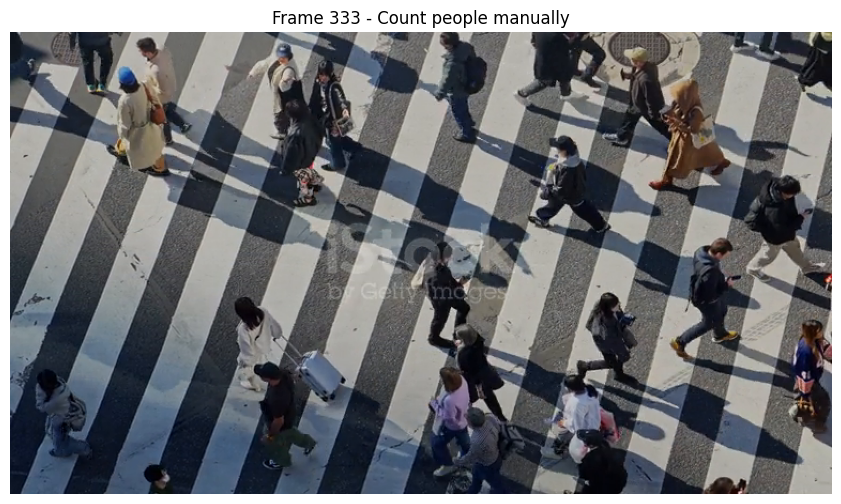

In [4]:
import cv2
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(video_path)

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

sample_indices = [
    int(total_frames * 0.10),
    int(total_frames * 0.30),
    int(total_frames * 0.50),
    int(total_frames * 0.70),
    int(total_frames * 0.90)
]

sample_frames = []

for index in sample_indices:
    cap.set(cv2.CAP_PROP_POS_FRAMES, index)
    ret, frame = cap.read()

    if ret:
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        sample_frames.append((index, frame))

cap.release()

for index, frame in sample_frames:
    plt.figure(figsize=(12, 6))
    plt.imshow(frame)
    plt.title(f"Frame {index} - Count people manually")
    plt.axis("off")
    plt.show()

In [5]:
from ultralytics import YOLO
import cv2
import time
import pandas as pd

model = YOLO("yolo11n.pt")

video_path = "/content/input.mp4"

cap = cv2.VideoCapture(video_path)

total_frames = 0
total_detections = 0
frame_results = []

start_time = time.perf_counter()

while True:
    ret, frame = cap.read()

    if not ret:
        break

    results = model.predict(
        frame,
        classes=[0],
        conf=0.35,
        imgsz=640,
        verbose=False
    )

    count = len(results[0].boxes)

    total_detections += count
    total_frames += 1

    frame_results.append({
        "Frame": total_frames,
        "Detected People": count
    })

end_time = time.perf_counter()

cap.release()

elapsed_time = end_time - start_time
processing_fps = total_frames / elapsed_time

print("Baseline Results")
print("-----------------------")
print("Processed Frames:", total_frames)
print("Total Frame Detections:", total_detections)
print("Processing Time:", round(elapsed_time, 2), "seconds")
print("Processing FPS:", round(processing_fps, 2))

baseline_df = pd.DataFrame(frame_results)
baseline_df.to_csv("/content/baseline_counts.csv", index=False)

Baseline Results
-----------------------
Processed Frames: 371
Total Frame Detections: 4398
Processing Time: 14.55 seconds
Processing FPS: 25.5


In [6]:
sample_indices = [37, 111, 185, 259, 333]

for frame_no in sample_indices:
    count = baseline_df.loc[
        baseline_df["Frame"] == frame_no,
        "Detected People"
    ].values[0]

    print(f"Frame {frame_no}: {count} detected people")

Frame 37: 10 detected people
Frame 111: 13 detected people
Frame 185: 10 detected people
Frame 259: 13 detected people
Frame 333: 14 detected people


In [7]:
import cv2
import time
import pandas as pd
from ultralytics import YOLO

def run_experiment(model_name, confidence, image_size, output_name):

    model = YOLO(model_name)
    cap = cv2.VideoCapture("/content/input.mp4")

    frame_no = 0
    total_detections = 0
    results_data = []

    start = time.perf_counter()

    while True:
        ret, frame = cap.read()

        if not ret:
            break

        frame_no += 1

        results = model.predict(
            frame,
            classes=[0],
            conf=confidence,
            imgsz=image_size,
            verbose=False
        )

        count = len(results[0].boxes)
        total_detections += count

        if frame_no in [37, 111, 185, 259, 333]:
            results_data.append({
                "Frame": frame_no,
                "Detected People": count
            })

    end = time.perf_counter()
    cap.release()

    fps = frame_no / (end - start)

    df = pd.DataFrame(results_data)
    df.to_csv(f"/content/{output_name}.csv", index=False)

    print("Model:", model_name)
    print("Confidence:", confidence)
    print("Image size:", image_size)
    print("Frames processed:", frame_no)
    print("Total detections:", total_detections)
    print("Processing time:", round(end-start, 2), "seconds")
    print("Processing FPS:", round(fps, 2))
    print("\nSample frame detections:")
    print(df.to_string(index=False))

    return fps, df

In [9]:
def run_experiment_warm(model_name, confidence, image_size, output_name):

    model = YOLO(model_name)
    cap = cv2.VideoCapture("/content/input.mp4")

    # Warm-up (not included in timing)
    ret, frame = cap.read()
    if ret:
        model.predict(
            frame,
            classes=[0],
            conf=confidence,
            imgsz=image_size,
            verbose=False
        )

    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

    frame_no = 0
    total_detections = 0
    sample_data = []

    start = time.perf_counter()

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        frame_no += 1

        results = model.predict(
            frame,
            classes=[0],
            conf=confidence,
            imgsz=image_size,
            verbose=False
        )

        count = len(results[0].boxes)
        total_detections += count

        if frame_no in [37, 111, 185, 259, 333]:
            sample_data.append({
                "Frame": frame_no,
                "Detected People": count
            })

    elapsed = time.perf_counter() - start
    cap.release()

    fps = frame_no / elapsed

    df = pd.DataFrame(sample_data)
    df.to_csv(f"/content/{output_name}.csv", index=False)

    print("Model:", model_name)
    print("Confidence:", confidence)
    print("Image size:", image_size)
    print("Processed frames:", frame_no)
    print("Total detections:", total_detections)
    print("Processing time:", round(elapsed, 2), "seconds")
    print("Processing FPS:", round(fps, 2))
    print("\nSample detections:")
    print(df.to_string(index=False))

    return fps, df

In [8]:
exp1_fps, exp1_df = run_experiment(
    model_name="yolo11n.pt",
    confidence=0.45,
    image_size=640,
    output_name="experiment1_confidence"
)

Model: yolo11n.pt
Confidence: 0.45
Image size: 640
Frames processed: 371
Total detections: 2963
Processing time: 5.82 seconds
Processing FPS: 63.76

Sample frame detections:
 Frame  Detected People
    37                7
   111                7
   185                6
   259               10
   333                8


### Observation — Experiment 1

Increasing the confidence threshold from 0.35 to 0.45 reduced the total number of detections from 4,398 to 2,963.

The processing FPS increased from 25.50 to 63.76 in the initial runs. However, the number of detected people in the five sample frames also decreased.

This suggests that a higher confidence threshold can reduce detections, including potentially correct detections. Faster processing does not necessarily mean better detection accuracy.

The initial FPS measurements may include different startup and warm-up overheads, so final performance comparisons will use a consistent timing method.

In [10]:
exp2_fps, exp2_df = run_experiment_warm(
    model_name="yolo11n.pt",
    confidence=0.35,
    image_size=960,
    output_name="experiment2_imgsize"
)

Model: yolo11n.pt
Confidence: 0.35
Image size: 960
Processed frames: 371
Total detections: 8068
Processing time: 6.29 seconds
Processing FPS: 59.01

Sample detections:
 Frame  Detected People
    37               18
   111               23
   185               21
   259               23
   333               25


### Observation — Experiment 2

Increasing the image size from 640 to 960 increased the total detections from 4,398 to 8,068.

The model detected more people in all five selected sample frames. Processing FPS was 59.01 in this run.

However, the estimated count error increased to 69.96% using the assumed reference counts. This indicates that increasing image size does not automatically improve counting accuracy. Additional detections may include false positives or duplicate detections.

Further evaluation is required to determine whether the additional detections are correct.

In [11]:
exp3_fps, exp3_df = run_experiment_warm(
    model_name="yolo11s.pt",
    confidence=0.35,
    image_size=640,
    output_name="experiment3_model"
)

Model: yolo11s.pt
Confidence: 0.35
Image size: 640
Processed frames: 371
Total detections: 4646
Processing time: 5.84 seconds
Processing FPS: 63.52

Sample detections:
 Frame  Detected People
    37               17
   111               11
   185                8
   259               14
   333               14


In [12]:

import torch
import cv2
import time
import pandas as pd
from ultralytics import YOLO

# Assumed reference counts (not actual manual counts)
reference_counts = [11, 14, 11, 14, 15]
sample_frames = [37, 111, 185, 259, 333]

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


def fair_experiment(model_name, confidence, image_size, experiment_name):

    model = YOLO(model_name)
    cap = cv2.VideoCapture("/content/input.mp4")

    # Warm-up prediction (excluded from timing)
    ret, frame = cap.read()
    if ret:
        model.predict(
            frame,
            classes=[0],
            conf=confidence,
            imgsz=image_size,
            verbose=False
        )

    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    frame_no = 0
    total_detections = 0
    sample_counts = []

    start = time.perf_counter()

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        frame_no += 1

        results = model.predict(
            frame,
            classes=[0],
            conf=confidence,
            imgsz=image_size,
            verbose=False
        )

        count = len(results[0].boxes)
        total_detections += count

        if frame_no in sample_frames:
            sample_counts.append(count)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start
    cap.release()

    fps = frame_no / elapsed

    errors = [
        abs(ref - detected) / ref * 100
        for ref, detected in zip(reference_counts, sample_counts)
    ]

    mape = sum(errors) / len(errors)

    print("\n", experiment_name)
    print("Model:", model_name)
    print("FPS:", round(fps, 2))
    print("Total detections:", total_detections)
    print("Estimated MAPE:", round(mape, 2), "%")
    print("Sample counts:", sample_counts)

    return {
        "Experiment": experiment_name,
        "Model": model_name,
        "Confidence": confidence,
        "Image Size": image_size,
        "FPS": round(fps, 2),
        "Total Detections": total_detections,
        "Estimated MAPE (%)": round(mape, 2)
    }


results = []

results.append(fair_experiment(
    "yolo11n.pt", 0.35, 640, "Baseline"
))

results.append(fair_experiment(
    "yolo11n.pt", 0.45, 640, "Experiment 1"
))

results.append(fair_experiment(
    "yolo11n.pt", 0.35, 960, "Experiment 2"
))

results.append(fair_experiment(
    "yolo11s.pt", 0.35, 640, "Experiment 3"
))

comparison = pd.DataFrame(results)
display(comparison)


GPU available: True
GPU: Tesla T4

 Baseline
Model: yolo11n.pt
FPS: 75.73
Total detections: 4398
Estimated MAPE: 7.83 %
Sample counts: [10, 13, 10, 13, 14]

 Experiment 1
Model: yolo11n.pt
FPS: 65.85
Total detections: 2963
Estimated MAPE: 41.41 %
Sample counts: [7, 7, 6, 10, 8]

 Experiment 2
Model: yolo11n.pt
FPS: 67.34
Total detections: 8068
Estimated MAPE: 69.96 %
Sample counts: [18, 23, 21, 23, 25]

 Experiment 3
Model: yolo11s.pt
FPS: 71.02
Total detections: 4646
Estimated MAPE: 21.98 %
Sample counts: [17, 11, 8, 14, 14]


,Experiment,Model,Confidence,Image Size,FPS,Total Detections,Estimated MAPE (%)
0,Baseline,yolo11n.pt,0.35,640,75.73,4398,7.83
1,Experiment 1,yolo11n.pt,0.45,640,65.85,2963,41.41
2,Experiment 2,yolo11n.pt,0.35,960,67.34,8068,69.96
3,Experiment 3,yolo11s.pt,0.35,640,71.02,4646,21.98


### Overall Conclusion

Three experiments were performed to evaluate the effect of confidence threshold, image size, and YOLO model selection on people detection performance.

The baseline configuration (YOLO11n, confidence 0.35, image size 640) achieved the highest processing speed of **75.73 FPS** and the lowest estimated MAPE of **7.83%** among the tested configurations.

Increasing the confidence threshold reduced the number of detections, while increasing image size resulted in substantially more detections. Changing the model to YOLO11s produced an estimated MAPE of 21.98%, which was better than Experiments 1 and 2 but worse than the baseline.

Overall, the baseline configuration provided the best measured balance between processing speed and estimated counting error. Therefore, it was selected as the best configuration for this experiment.

## Final Performance Comparison

All experiments were performed using Google Colab with an NVIDIA Tesla T4 GPU.

| Experiment | Model | Confidence | Image Size | FPS | Total Detections | Estimated MAPE (%) |
|---|---|---:|---:|---:|---:|---:|
| Baseline | YOLO11n | 0.35 | 640 | 75.73 | 4398 | 7.83 |
| Experiment 1 | YOLO11n | 0.45 | 640 | 65.85 | 2963 | 41.41 |
| Experiment 2 | YOLO11n | 0.35 | 960 | 67.34 | 8068 | 69.96 |
| Experiment 3 | YOLO11s | 0.35 | 640 | 71.02 | 4646 | 21.98 |

## Observations

**Experiment 1 – Confidence Threshold**

Increasing the confidence threshold from 0.35 to 0.45 reduced the total detections from 4398 to 2963. Processing speed also decreased from 75.73 to 65.85 FPS. The estimated MAPE increased to 41.41%.

**Experiment 2 – Image Size**

Increasing the image size from 640 to 960 increased the total detections to 8068. However, processing speed decreased to 67.34 FPS, and estimated MAPE increased to 69.96%.

**Experiment 3 – Model Selection**

Changing the model from YOLO11n to YOLO11s resulted in 4646 total detections and 71.02 FPS. Its estimated MAPE was 21.98%, which was better than Experiments 1 and 2 but worse than the baseline.

## Final Conclusion

The baseline configuration (YOLO11n, confidence 0.35, image size 640) achieved the highest processing speed and lowest estimated MAPE among the tested configurations.

Therefore, the baseline was the best-performing configuration in this experiment.

## Evaluation Limitation

The reference counts used to calculate MAPE were assumed illustrative counts rather than independently verified manual counts. Therefore, the reported MAPE values should be considered preliminary estimates, not verified detection accuracy.